# Prédire la valeur d'un joueur la saison suivante (Big 5)

Suite du projet *Valorisation des joueurs du Big 5 2025-26*. Le premier projet répondait à la question « combien vaut un joueur aujourd'hui au vu de ses performances ? ». Celui-ci répond à la question suivante : combien vaudra-t-il dans un an ?

Question métier : une cellule de recrutement veut savoir quels joueurs vont prendre de la valeur (à acheter tôt) et lesquels vont en perdre (à vendre avant la baisse).

Méthode :
1. On reconstruit, avec l'historique Transfermarkt, la cote de chaque joueur du Big 5 au 30 juin de chaque année, de 2014 à 2026.
2. On apprend à prédire la cote au 30 juin suivant.
   On y ajoute les statistiques de jeu de la saison écoulée (minutes, titularisations, buts et passes décisives) quand le fichier `appearances.csv` est disponible.
3. On teste honnêtement : le modèle apprend sur 2014-2024 et il est jugé sur la dernière saison (cote 2025 → cote 2026), qu'il n'a jamais vue.
4. On le compare à la référence la plus simple : « la cote ne bouge pas ».
5. On réentraîne sur tout l'historique et on prédit la cote au 30 juin 2027.

## Réglages et chargement

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor

# Les données Transfermarkt : dans ./donnees, sinon dans le dossier du premier projet
PREMIER_PROJET = [Path("../valorisation-joueurs-big5/Sources - Python"), Path("../valorisation-joueurs-big5/Sources"), Path("../Sources")]
DOSSIERS = [Path("donnees")] + [x for d in PREMIER_PROJET for x in (d / "Transfermarket", d)]
DONNEES = next(d for d in DOSSIERS if (d / "player_valuations.csv").exists() and (d / "players.csv").exists())
print("données lues dans :", DONNEES)

def trouver(nom):
    for d in [DONNEES] + DOSSIERS:
        if (d / nom).exists():
            return d / nom
    return None

APPEARANCES = trouver("appearances.csv")   # stats match par match (facultatif)
GAMES = trouver("games.csv")               # résultats des clubs (facultatif, pour un test)
print("appearances.csv :", APPEARANCES, "| games.csv :", GAMES)

BIG5 = {"GB1": "Premier League", "ES1": "LaLiga", "IT1": "Serie A", "L1": "Bundesliga", "FR1": "Ligue 1"}
GRANDS_CLUBS = {
    "Real Madrid", "FC Barcelona", "Atlético de Madrid", "Bayern Munich", "Borussia Dortmund",
    "Manchester City", "Liverpool FC", "Arsenal FC", "Chelsea FC", "Manchester United",
    "Inter Milan", "AC Milan", "Juventus FC", "Paris Saint-Germain",
}
ANNEES = range(2014, 2027)          # photos au 30 juin de 2014 à 2026
ANNEE_TEST = 2025                   # cote 2025 -> cote 2026, jamais vue à l'entraînement

données lues dans : donnees
appearances.csv : donnees/appearances.csv | games.csv : donnees/games.csv


In [2]:
valuations = pd.read_csv(DONNEES / "player_valuations.csv", parse_dates=["date"]).sort_values("date")
players = pd.read_csv(DONNEES / "players.csv", parse_dates=["date_of_birth"])
players = players[["player_id", "name", "date_of_birth", "position", "height_in_cm"]]
print("cotes datées :", len(valuations), "du", valuations["date"].min().date(), "au", valuations["date"].max().date())
print("joueurs :", len(players))

cotes datées : 656301 du 2000-01-20 au 2026-06-12
joueurs : 50149


## Une photo par joueur et par année

Pour chaque année, on prend la dernière cote connue de chaque joueur dans les 12 mois qui précèdent le 30 juin, avec son club et son championnat à ce moment-là. On garde les joueurs qui jouent alors dans le Big 5.

- Cible : la dernière cote dans les 12 mois avant le 30 juin suivant, à condition qu'elle soit postérieure à la photo.
- Élan : l'évolution de la cote sur l'année écoulée (photo de l'année précédente).
- Écart au pic : à quel point le joueur est sous sa meilleure cote passée.

Tout est calculé avec des informations disponibles au 30 juin : le modèle ne voit jamais le futur.

In [3]:
def photo(annee):
    fin = pd.Timestamp(f"{annee}-06-30")
    fenetre = valuations[(valuations["date"] <= fin) & (valuations["date"] > fin - pd.Timedelta(days=365))]
    return fenetre.groupby("player_id").tail(1).set_index("player_id")

photos = {a: photo(a) for a in range(min(ANNEES) - 1, max(ANNEES) + 2)}

lignes = []
for a in ANNEES:
    p = photos[a][photos[a]["player_club_domestic_competition_id"].isin(BIG5)]
    df = pd.DataFrame({
        "annee": a,
        "valeur": p["market_value_in_eur"],
        "ligue": p["player_club_domestic_competition_id"].map(BIG5),
        "club": p["current_club_name"],
    })
    df["valeur_prec"] = photos[a - 1]["market_value_in_eur"].reindex(df.index)
    suivante = photos[a + 1]
    df["cible"] = suivante["market_value_in_eur"].reindex(df.index)
    date_cible = suivante["date"].reindex(df.index)
    df.loc[date_cible <= pd.Timestamp(f"{a}-06-30"), "cible"] = np.nan
    passe = valuations[valuations["date"] <= pd.Timestamp(f"{a}-06-30")].groupby("player_id")["market_value_in_eur"]
    df["pic"] = passe.max().reindex(df.index)
    df["nb_cotes"] = passe.size().reindex(df.index)
    lignes.append(df.reset_index())

panel = pd.concat(lignes).merge(players, on="player_id", how="left")
panel["age"] = (pd.to_datetime(panel["annee"].astype(str) + "-06-30") - panel["date_of_birth"]).dt.days / 365.25
panel = panel[(panel["valeur"] > 0) & panel["age"].notna()].copy()

panel["log_valeur"] = np.log(panel["valeur"])
panel["elan"] = np.log(panel["valeur"] / panel["valeur_prec"])
panel["elan_connu"] = panel["elan"].notna().astype(int)
panel["elan"] = panel["elan"].fillna(0)
panel["sous_pic"] = np.log(panel["pic"] / panel["valeur"])
panel["grand_club"] = panel["club"].isin(GRANDS_CLUBS).astype(int)
panel["evolution"] = np.log(panel["cible"] / panel["valeur"])   # ce qu'on prédit : l'évolution en log

print(panel.groupby("annee").agg(joueurs=("valeur", "size"), avec_cible=("cible", "count")).T)

annee       2014  2015  2016  2017  2018  ...  2022  2023  2024  2025  2026
joueurs     4053  4666  5018  5702  5675  ...  6707  6893  4125  3009  3014
avec_cible  3793  4291  4733  5131  5236  ...  6156  3925  2854  2976     0

[2 rows x 13 columns]


## Les statistiques de jeu de la saison écoulée

Pour chaque photo au 30 juin, on additionne les matchs joués par le joueur entre le 1er juillet précédent et ce 30 juin, toutes compétitions confondues : minutes, matchs, titularisations (60 minutes ou plus), buts et passes décisives par 90 minutes, et l'évolution du temps de jeu par rapport à la saison d'avant.

In [4]:
STATS_JEU = []
if APPEARANCES is not None:
    app = pd.read_csv(APPEARANCES, usecols=["player_id", "date", "goals", "assists", "minutes_played"], parse_dates=["date"])
    saisons = []
    for a in range(min(ANNEES) - 1, max(ANNEES) + 1):
        s = app[(app["date"] > pd.Timestamp(f"{a - 1}-06-30")) & (app["date"] <= pd.Timestamp(f"{a}-06-30"))]
        g = s.groupby("player_id").agg(matchs=("minutes_played", "size"), minutes=("minutes_played", "sum"),
                                       buts=("goals", "sum"), passes=("assists", "sum"),
                                       titularisations=("minutes_played", lambda m: (m >= 60).sum()))
        g["annee"] = a
        saisons.append(g.reset_index())
    saisons = pd.concat(saisons)
    precedent = saisons[["player_id", "annee", "minutes"]].assign(annee=saisons["annee"] + 1).rename(columns={"minutes": "minutes_prec"})
    panel = panel.drop(columns=[c for c in ["matchs", "minutes", "buts", "passes", "titularisations", "minutes_prec"] if c in panel])
    panel = panel.merge(saisons, on=["player_id", "annee"], how="left").merge(precedent, on=["player_id", "annee"], how="left")
    for c in ["matchs", "minutes", "buts", "passes", "titularisations", "minutes_prec"]:
        panel[c] = panel[c].fillna(0)
    panel["minutes_k"] = panel["minutes"] / 1000
    panel["evol_minutes_k"] = (panel["minutes"] - panel["minutes_prec"]) / 1000
    panel["decisif_90"] = np.where(panel["minutes"] >= 300, (panel["buts"] + panel["passes"]) / panel["minutes"] * 90, 0)
    STATS_JEU = ["minutes_k", "evol_minutes_k", "decisif_90", "matchs", "titularisations"]
    print("matchs lus :", len(app), "| photos avec du temps de jeu :", round((panel["minutes"] > 0).mean() * 100), "%",
          "| parmi les joueurs à 5 M€ ou plus :", round((panel.loc[panel["valeur"] >= 5e6, "minutes"] > 0).mean() * 100), "%")
else:
    print("appearances.csv absent : le modèle tourne sans statistiques de jeu")

matchs lus : 1894350 | photos avec du temps de jeu : 47 % | parmi les joueurs à 5 M€ ou plus : 95 %


L'année 2026 n'a pas de cible : c'est celle qu'on prédira à la fin. Les années 2023 et 2024 ont moins de cibles que les autres : ce jeu de données contient moins de cotes publiées à partir de 2024.

## Ce que montrent les données

age
18.0    59.0
19.0    41.0
20.0    34.0
21.0    28.0
22.0    21.0
23.0    13.0
24.0     9.0
25.0     4.0
26.0    -0.0
27.0    -5.0
28.0    -9.0
29.0   -18.0
30.0   -24.0
31.0   -28.0
32.0   -33.0
33.0   -36.0
34.0   -37.0
35.0   -35.0


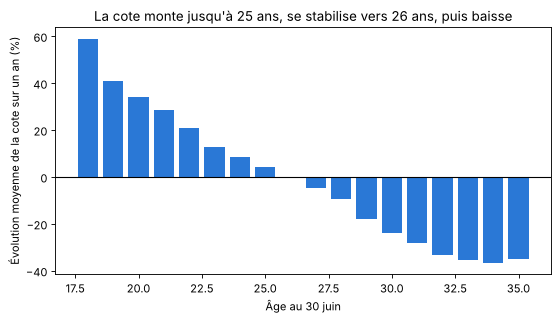

In [5]:
hist = panel.dropna(subset=["cible"])
par_age = hist.groupby(hist["age"].round())["evolution"].mean()
par_age = par_age[(par_age.index >= 18) & (par_age.index <= 35)]
plt.figure(figsize=(8, 4))
plt.bar(par_age.index, (np.exp(par_age.values) - 1) * 100, color="#2a78d6")
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Âge au 30 juin")
plt.ylabel("Évolution moyenne de la cote sur un an (%)")
plt.title("La cote monte jusqu'à 25 ans, se stabilise vers 26 ans, puis baisse")
plt.show()
print(((np.exp(par_age) - 1) * 100).round(0).to_string())

L'âge est le premier moteur : en moyenne, la cote prend environ 40 % en un an à 19 ans, ne bouge plus vers 26 ans, et perd près de 30 % à 31 ans. (La médiane, elle, vaut souvent 0 entre 20 et 27 ans : Transfermarkt ne change pas la cote d'une bonne partie des joueurs d'une année sur l'autre.)

## Les variables du modèle

Toutes connues au 30 juin de l'année de la photo :
- la cote (en log), l'élan sur un an, l'écart au pic, le nombre de cotes déjà publiées (ancienneté du joueur dans la base) ;
- l'âge et l'âge au carré (la courbe monte puis descend) ;
- le poste, le championnat, le grand club, la taille ;
- les statistiques de jeu de la saison écoulée (si `appearances.csv` est présent).

In [6]:
BASE = ["log_valeur", "elan", "elan_connu", "sous_pic", "nb_cotes", "age", "grand_club", "height_in_cm"]
VARIABLES = BASE + STATS_JEU

def matrice(df, variables=None):
    x = df[variables or VARIABLES].copy()
    x["height_in_cm"] = x["height_in_cm"].fillna(182)
    x["age2"] = (x["age"] - 26) ** 2
    x = x.join(pd.get_dummies(df["position"], prefix="poste", dtype=int))
    x = x.join(pd.get_dummies(df["ligue"], prefix="ligue", dtype=int))
    return x.fillna(0)

connus = panel.dropna(subset=["cible"]).copy()
X = matrice(connus)
y = connus["evolution"]
entrainement = connus["annee"] < ANNEE_TEST
test = connus["annee"] == ANNEE_TEST
print("entraînement :", entrainement.sum(), "photos (2014-2024) | test :", test.sum(), "joueurs (cote 2025 -> 2026)")

entraînement : 53505 photos (2014-2024) | test : 2976 joueurs (cote 2025 -> 2026)


## Test sur la dernière saison

Trois mesures, toutes sur des joueurs que le modèle n'a jamais vus :
- erreur médiane : de combien la prédiction se trompe pour un joueur typique (×1,30 = 30 % au-dessus ou en dessous) ;
- erreur moyenne en log : la même idée, en moyenne, plus sensible aux grosses erreurs ;
- sens : parmi les joueurs dont la cote a bougé de plus de 5 %, la part pour laquelle le modèle avait annoncé le bon sens (hausse ou baisse).

In [7]:
def mesurer(nom, prevision, vrai):
    erreur = np.abs(prevision - vrai)
    bouge = np.abs(vrai) > 0.05
    sens = (np.sign(prevision[bouge]) == np.sign(vrai[bouge])).mean() if np.any(prevision != 0) else np.nan
    return {"modèle": nom, "erreur médiane (×)": round(float(np.exp(np.median(erreur))), 2),
            "erreur moyenne (log)": round(float(erreur.mean()), 3), "bon sens (%)": round(100 * sens) if sens == sens else "—"}

vrai = y[test].values
resultats = [mesurer("La cote ne bouge pas", np.zeros(len(vrai)), vrai)]

courbe_age = connus[entrainement].groupby(connus[entrainement]["age"].round())["evolution"].median()
resultats.append(mesurer("Courbe d'âge seule", connus.loc[test, "age"].round().map(courbe_age).fillna(0).values, vrai))

regression = LinearRegression().fit(X[entrainement], y[entrainement])
resultats.append(mesurer("Régression linéaire", regression.predict(X[test]), vrai))

def boosting_sur(variables):
    Xv = matrice(connus, variables)
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=40, random_state=42)
    return m.fit(Xv[entrainement], y[entrainement]).predict(Xv[test])

if STATS_JEU:
    resultats.append(mesurer("Gradient boosting, sans stats de jeu", boosting_sur(BASE), vrai))
resultats.append(mesurer("Gradient boosting" + (", avec stats de jeu" if STATS_JEU else ""), boosting_sur(VARIABLES), vrai))

pd.DataFrame(resultats)

,modèle,erreur médiane (×),erreur moyenne (log),bon sens (%)
0,La cote ne bouge pas,1.40,0.442,—
1,Courbe d'âge seule,1.33,0.394,35
2,Régression linéaire,1.32,0.387,73
3,"Gradient boosting, sans stats de jeu",1.31,0.381,73
4,"Gradient boosting, avec stats de jeu",1.30,0.378,73


Lecture :
- Dire « la cote ne bouge pas » se trompe d'un facteur 1,40 pour un joueur typique. C'est la référence à battre.
- La courbe d'âge seule fait déjà mieux. Le gradient boosting fait le mieux : environ ×1,30, soit une erreur moyenne réduite d'environ 14 % par rapport à la référence.
- Les statistiques de jeu n'apportent qu'un petit gain (environ 1 % d'erreur en moins). Ce n'est pas qu'elles ne comptent pas : Transfermarkt met à jour la cote au fil de la saison en fonction des performances, donc au 30 juin, la saison écoulée est déjà en grande partie dans la cote. Les buts d'une saison font monter la cote *pendant* cette saison, pas l'année suivante.
- Quand la cote bouge vraiment, le modèle annonce le bon sens près de trois fois sur quatre.
- La régression linéaire est presque aussi bonne et reste lisible : l'écart entre les deux modèles est faible.

Le modèle ne devine pas les événements (une blessure, un transfert, une saison exceptionnelle). Il capte surtout l'âge, l'élan et le rattrapage des joueurs tombés sous leur pic.

## Une fourchette plutôt qu'un chiffre

Une prédiction seule cache l'incertitude. On entraîne donc deux modèles de plus, un pour le bas de la fourchette (10 % des cas en dessous) et un pour le haut (10 % au-dessus), et on vérifie sur la saison test que 80 % des vraies cotes tombent bien dedans.

In [8]:
def quantile(q):
    m = HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=300, learning_rate=0.05,
                                      min_samples_leaf=40, random_state=42)
    return m.fit(X[entrainement], y[entrainement])

bas, haut = quantile(0.10), quantile(0.90)
dedans = (vrai >= bas.predict(X[test])) & (vrai <= haut.predict(X[test]))
print(f"part des vraies cotes 2026 dans la fourchette annoncée : {dedans.mean():.0%} (visé : 80 %)")

part des vraies cotes 2026 dans la fourchette annoncée : 79% (visé : 80 %)


### En images : la saison test

Trois vérifications visuelles sur les 2 976 joueurs de la saison test (cote 2025 -> 2026), que le modèle n'a jamais vus :
1. la cote prédite contre la vraie cote ;
2. l'erreur selon l'âge : où le modèle se trompe-t-il le plus ?
3. la fourchette : est-ce que les vraies cotes tombent dedans ?

corrélation (log) prédite / vraie : 0.937


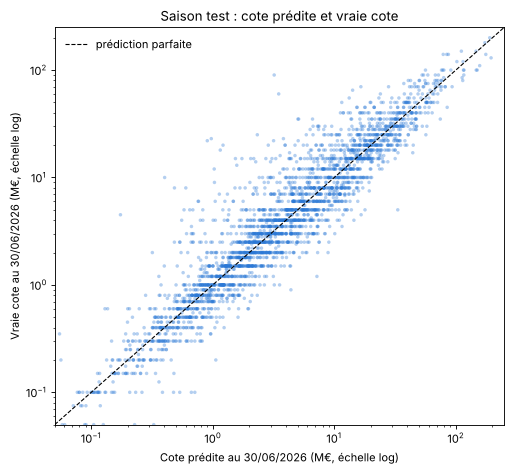

In [9]:
# Prédictions du modèle retenu sur la saison test, remises en euros
prev_test = boosting_sur(VARIABLES)
t = connus.loc[test, ["age", "valeur"]].copy()
t["vraie_2026"] = t["valeur"] * np.exp(vrai)
t["predite_2026"] = t["valeur"] * np.exp(prev_test)
t["erreur_log"] = prev_test - vrai          # > 0 : le modèle surestime

plt.figure(figsize=(6.5, 6))
plt.scatter(t["predite_2026"] / 1e6, t["vraie_2026"] / 1e6, s=10, alpha=0.35, color="#2a78d6", edgecolors="none")
lim = [0.05, 250]
plt.plot(lim, lim, color="black", linewidth=1, linestyle="--", label="prédiction parfaite")
plt.xscale("log"); plt.yscale("log"); plt.xlim(lim); plt.ylim(lim)
plt.xlabel("Cote prédite au 30/06/2026 (M€, échelle log)")
plt.ylabel("Vraie cote au 30/06/2026 (M€, échelle log)")
plt.title("Saison test : cote prédite et vraie cote")
plt.legend(loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig("images/predite_vs_reelle.png", dpi=150)
plt.show()
print("corrélation (log) prédite / vraie :", round(np.corrcoef(np.log(t["predite_2026"]), np.log(t["vraie_2026"]))[0, 1], 3))

Les points suivent la diagonale sur toute l'échelle, de 100 000 € à plus de 100 M€. C'est en partie normal : la cote de l'an dernier est déjà une très bonne indication. Le vrai travail du modèle, c'est l'écart à cette diagonale, que regardent les deux graphiques suivants.

             joueurs  erreur_mediane  erreur_typique
tranche_age                                         
≤21              310             1.2            60.4
22-24            632             2.4            39.0
25-28           1009             2.5            30.4
29-32            656            -3.5            22.8
33+              369            -7.2            21.7


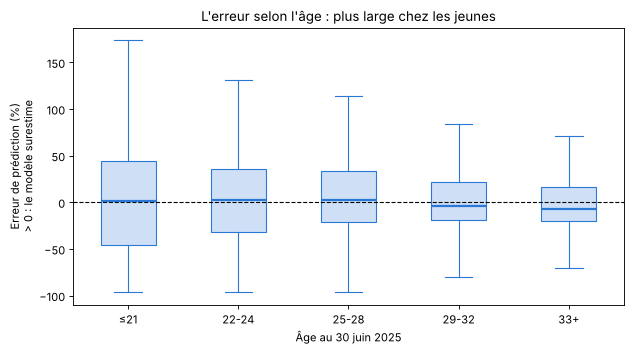

In [10]:
t["tranche_age"] = pd.cut(t["age"], [15, 21, 24, 28, 32, 45], labels=["≤21", "22-24", "25-28", "29-32", "33+"])
groupes = [((np.exp(g) - 1) * 100).values for _, g in t.groupby("tranche_age", observed=True)["erreur_log"]]
noms = [str(n) for n in t["tranche_age"].cat.categories]

plt.figure(figsize=(8, 4.5))
plt.boxplot(groupes, tick_labels=noms, showfliers=False, patch_artist=True,
            boxprops=dict(facecolor="#cfe0f6", color="#2a78d6"), medianprops=dict(color="#2a78d6", linewidth=2),
            whiskerprops=dict(color="#2a78d6"), capprops=dict(color="#2a78d6"))
plt.axhline(0, color="black", linewidth=1, linestyle="--")
plt.xlabel("Âge au 30 juin 2025")
plt.ylabel("Erreur de prédiction (%)\n> 0 : le modèle surestime")
plt.title("L'erreur selon l'âge : plus large chez les jeunes")
plt.tight_layout()
plt.savefig("images/erreur_par_age.png", dpi=150)
plt.show()
resume = t.groupby("tranche_age", observed=True)["erreur_log"].agg(
    joueurs="size", erreur_mediane=lambda e: (np.exp(np.median(e)) - 1) * 100,
    erreur_typique=lambda e: (np.exp(np.median(np.abs(e))) - 1) * 100)
print(resume.round(1).to_string())

Lecture : la boîte du milieu de chaque tranche contient la moitié des joueurs. Plus elle est haute, plus le modèle hésite pour cet âge. Les jeunes sont les plus difficiles à prévoir : leur cote peut doubler ou stagner selon une saison. Pour les plus âgés, la baisse est plus régulière, donc plus facile à anticiper. Une médiane au-dessus de 0 veut dire que le modèle surestime en moyenne cette tranche.

en dessous             9.7
dans la fourchette    79.2
au-dessus             11.1


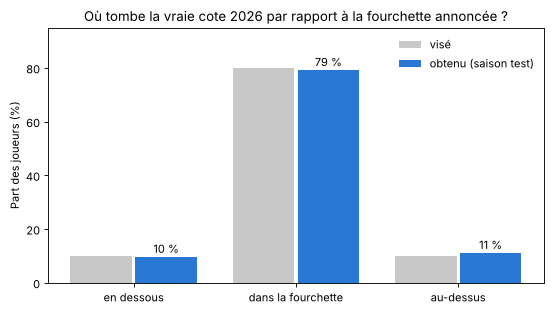

In [11]:
t["bas"] = t["valeur"] * np.exp(bas.predict(X[test]))
t["haut"] = t["valeur"] * np.exp(haut.predict(X[test]))
position = np.select([t["vraie_2026"] < t["bas"], t["vraie_2026"] > t["haut"]], ["en dessous", "au-dessus"], "dans la fourchette")
parts = pd.Series(position).value_counts(normalize=True).reindex(["en dessous", "dans la fourchette", "au-dessus"]) * 100
vise = pd.Series([10, 80, 10], index=parts.index)

x = np.arange(3)
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, vise, width=0.38, color="#c8c8c8", label="visé")
plt.bar(x + 0.2, parts.values, width=0.38, color="#2a78d6", label="obtenu (saison test)")
for i, v in enumerate(parts.values):
    plt.text(i + 0.2, v + 1.5, f"{v:.0f} %", ha="center", fontsize=10)
plt.xticks(x, parts.index)
plt.ylabel("Part des joueurs (%)")
plt.title("Où tombe la vraie cote 2026 par rapport à la fourchette annoncée ?")
plt.legend(frameon=False)
plt.ylim(0, 95)
plt.tight_layout()
plt.savefig("images/fourchette.png", dpi=150)
plt.show()
print(parts.round(1).to_string())

Si la fourchette était trop étroite, beaucoup de vraies cotes tomberaient en dehors ; trop large, presque toutes tomberaient dedans et elle ne servirait à rien. Ici, on est proche des 10 / 80 / 10 visés : la fourchette annoncée est honnête.

## Ce qui pèse dans la prédiction

On utilise la régression linéaire, plus lisible que le boosting. L'effet de l'âge se lit sur le graphique plus haut ; voici le poids des autres variables, à âge égal.

In [12]:
lecture = pd.Series(regression.coef_, index=X.columns)
for nom, pas, texte in [("elan", np.log(1.5), "cote en hausse de 50 % sur l'année écoulée"),
                        ("grand_club", 1, "joueur de grand club"),
                        ("log_valeur", np.log(2), "cote deux fois plus haute")]:
    print(f"{texte:45s} : {(np.exp(lecture[nom] * pas) - 1) * 100:+.0f} % sur l'année suivante, à âge égal")

cote en hausse de 50 % sur l'année écoulée    : +4 % sur l'année suivante, à âge égal
joueur de grand club                          : +6 % sur l'année suivante, à âge égal
cote deux fois plus haute                     : -4 % sur l'année suivante, à âge égal


- L'âge écrase tout le reste : c'est lui qui décide du sens de l'évolution (graphique plus haut).
- L'élan et le grand club jouent à la marge, de quelques points : une hausse se prolonge un peu, un joueur de grand club progresse un peu plus.
- Niveau de cote : plus une cote est haute, moins elle progresse en pourcentage.

## Prédiction de la cote au 30 juin 2027

On réentraîne sur tout l'historique connu (photos 2014-2025), puis on applique le modèle à la photo du 30 juin 2026.

### En image : ce qui compte le plus pour le modèle

On mélange une variable à la fois sur la saison test et on regarde de combien l'erreur augmente : plus elle augmente, plus le modèle dépendait de cette variable (importance par permutation). Les colonnes poste et championnat sont regroupées.

Âge                          0.0587
Cote actuelle                0.0418
Ancienneté dans la base      0.0064
Minutes jouées               0.0041
Écart au pic de carrière     0.0034
Matchs joués                 0.0022
Poste                        0.0016
Âge (courbe)                 0.0016
Évolution du temps de jeu    0.0010
Élan sur un an               0.0009
Championnat                  0.0007
Buts + passes déc. / 90      0.0007
Grand club                   0.0005
Élan connu (oui/non)         0.0005


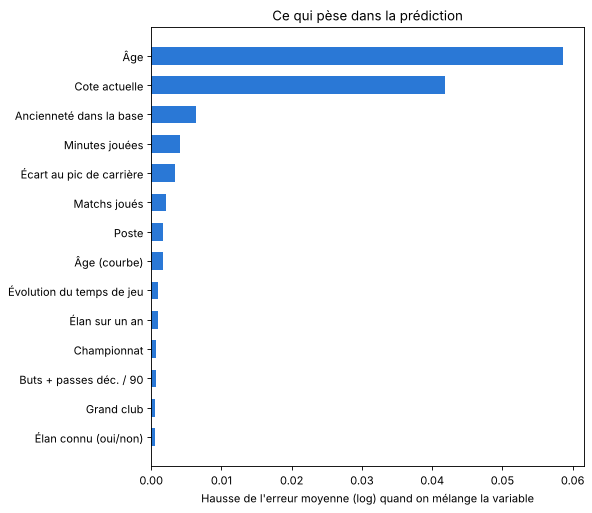

In [13]:
from sklearn.inspection import permutation_importance

modele_retenu = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=40, random_state=42)
modele_retenu.fit(X[entrainement], y[entrainement])
imp = permutation_importance(modele_retenu, X[test], y[test], scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=42)
imp = pd.Series(imp.importances_mean, index=X.columns)

noms_clairs = {"log_valeur": "Cote actuelle", "elan": "Élan sur un an", "elan_connu": "Élan connu (oui/non)",
               "sous_pic": "Écart au pic de carrière", "nb_cotes": "Ancienneté dans la base", "age": "Âge",
               "age2": "Âge (courbe)", "grand_club": "Grand club", "height_in_cm": "Taille",
               "minutes_k": "Minutes jouées", "matchs": "Matchs joués", "titularisations": "Titularisations",
               "decisif_90": "Buts + passes déc. / 90", "evol_minutes_k": "Évolution du temps de jeu"}
groupe = lambda c: "Poste" if c.startswith("poste_") else "Championnat" if c.startswith("ligue_") else noms_clairs.get(c, c)
imp = imp.groupby(imp.index.map(groupe)).sum().sort_values()
imp = imp[imp > 0]

plt.figure(figsize=(7.5, 0.38 * len(imp) + 1.2))
plt.barh(imp.index, imp.values, color="#2a78d6", height=0.6)
plt.xlabel("Hausse de l'erreur moyenne (log) quand on mélange la variable")
plt.title("Ce qui pèse dans la prédiction")
plt.tight_layout()
plt.savefig("images/importance_variables.png", dpi=150)
plt.show()
print(imp.sort_values(ascending=False).round(4).to_string())

Lecture : l'âge et la cote actuelle font l'essentiel du travail. Viennent ensuite, loin derrière, l'ancienneté dans la base, le temps de jeu et l'écart au pic de carrière. Le poste, le championnat et le grand club pèsent peu *une fois l'âge et la cote connus* : leur effet est déjà en grande partie dans la cote de départ. Cela confirme le constat du tableau des modèles : pour prédire l'année suivante, la trajectoire compte plus que la dernière saison.

In [14]:
X_tout, y_tout = matrice(connus), connus["evolution"]
final = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=40, random_state=42).fit(X_tout, y_tout)
final_bas = HistGradientBoostingRegressor(loss="quantile", quantile=0.10, max_iter=300, learning_rate=0.05,
                                         min_samples_leaf=40, random_state=42).fit(X_tout, y_tout)
final_haut = HistGradientBoostingRegressor(loss="quantile", quantile=0.90, max_iter=300, learning_rate=0.05,
                                          min_samples_leaf=40, random_state=42).fit(X_tout, y_tout)

a_predire = panel[panel["annee"] == 2026].copy()
Xp = matrice(a_predire).reindex(columns=X_tout.columns, fill_value=0)
a_predire["cote_2027"] = a_predire["valeur"] * np.exp(final.predict(Xp))
a_predire["bas_2027"] = a_predire["valeur"] * np.exp(final_bas.predict(Xp))
a_predire["haut_2027"] = a_predire["valeur"] * np.exp(final_haut.predict(Xp))
a_predire["evolution_pct"] = (a_predire["cote_2027"] / a_predire["valeur"] - 1) * 100

a_predire["position"] = a_predire["position"].map({"Attack": "Attaquant", "Midfield": "Milieu", "Defender": "Défenseur", "Goalkeeper": "Gardien"})
sortie = a_predire[["player_id", "name", "position", "ligue", "club", "age", "valeur",
                    "cote_2027", "bas_2027", "haut_2027", "evolution_pct"]].rename(columns={
    "player_id": "tm_id", "name": "joueur", "position": "poste", "valeur": "cote_2026"})
sortie = sortie.sort_values("cote_2026", ascending=False)
sortie.round({"age": 1, "evolution_pct": 1, "cote_2027": -5, "bas_2027": -5, "haut_2027": -5}).to_csv("predictions_2027.csv", index=False)
print(len(sortie), "joueurs prédits -> predictions_2027.csv")

3014 joueurs prédits -> predictions_2027.csv


## Listes de travail pour le mercato

Les prédictions servent à orienter le travail des recruteurs, pas à décider seules : la fourchette reste large.

In [15]:
m = lambda x: (x / 1e6).round(1)
vue = sortie.assign(cote_2026_M=m(sortie["cote_2026"]), cote_2027_M=m(sortie["cote_2027"]),
                    fourchette_M=m(sortie["bas_2027"]).astype(str) + " – " + m(sortie["haut_2027"]).astype(str))
cols = ["joueur", "poste", "club", "age", "cote_2026_M", "cote_2027_M", "fourchette_M", "evolution_pct"]

hausse = vue[(vue["cote_2026"] >= 5e6) & (vue["evolution_pct"] >= 25)].sort_values("evolution_pct", ascending=False)
print("1. Hausse prévue de 25 % ou plus (cote 2026 ≥ 5 M€) :", len(hausse), "joueurs")
print(hausse[cols].head(12).round(1).to_string(index=False))
print(f"   part des moins de 22 ans : {(hausse['age'] < 22).mean():.0%}")

baisse = vue[(vue["cote_2026"] >= 10e6) & (vue["haut_2027"] < vue["cote_2026"])].sort_values("evolution_pct")
print("\n2. Baisse attendue même dans le haut de la fourchette (cote 2026 ≥ 10 M€) :", len(baisse), "joueurs")
print(baisse[cols].head(12).round(1).to_string(index=False))
print(f"   âges : {baisse['age'].min():.0f} à {baisse['age'].max():.0f} ans | baisse moyenne prévue : {baisse['evolution_pct'].mean():.0f} %")

1. Hausse prévue de 25 % ou plus (cote 2026 ≥ 5 M€) : 104 joueurs
         joueur     poste                     club  age  cote_2026_M  cote_2027_M fourchette_M  evolution_pct
     Max Dowman Attaquant               Arsenal FC 16.5         30.0         81.4 26.7 – 207.7          171.2
Believe Munongo    Milieu                  FC Metz 16.6         10.0         22.4   7.7 – 43.7          123.6
     Wael Mohya    Milieu Borussia Mönchengladbach 17.5         17.0         34.5  12.2 – 69.6          103.0
      Chido Obi Attaquant        Manchester United 18.6          5.0          8.6   4.0 – 21.8           72.1
  Kaïl Boudache Attaquant                 OGC Nice 20.0          5.0          8.4   3.1 – 21.3           67.2
      Axel Tape Défenseur      Bayer 04 Leverkusen 18.9          8.0         13.0   5.2 – 30.3           63.1
    David Odogu Défenseur                 AC Milan 20.1          5.0          8.1   3.6 – 21.7           62.7
 Seny Koumbassa Défenseur              FC Toulouse 19.

Lecture :
- Liste 1 : des joueurs dont la cote devrait monter d'au moins un quart. Ce sont surtout de jeunes joueurs : des cibles à acheter tôt, avant que leur prix ne suive.
- Liste 2 : des joueurs dont la cote devrait baisser même dans le scénario favorable. Ce sont surtout des joueurs de 29 ans et plus : un club qui les possède a intérêt à vendre maintenant plutôt que dans un an.

## Croisement avec le premier projet

Le premier projet repérait des joueurs payés sous leur valeur statistique (cote < règle). Croisés avec une hausse prévue, ils forment la liste la plus intéressante : sous-cotés aujourd'hui et en progression attendue.

In [16]:
chemin = None
for c in [d / "joueurs_modele.csv" for d in DOSSIERS]:
    if c.exists():
        chemin = c
        break
if chemin is None:
    print("joueurs_modele.csv introuvable : copier le fichier du premier projet dans ./donnees")
else:
    regle = pd.read_csv(chemin)[["tm_id", "multiplicateur", "fb_minutes"]]
    croise = vue.merge(regle, on="tm_id", how="inner")
    cibles = croise[(croise["multiplicateur"] < 0.7) & (croise["evolution_pct"] > 0)
                    & (croise["fb_minutes"] >= 1500)].sort_values("evolution_pct", ascending=False)
    print(len(croise), "joueurs présents dans les deux projets |", len(cibles),
          "sous-cotés (cote < 0,7 × règle), titulaires, avec une hausse prévue")
    print(cibles[cols + ["multiplicateur"]].head(15).round(2).to_string(index=False))

1160 joueurs présents dans les deux projets | 77 sous-cotés (cote < 0,7 × règle), titulaires, avec une hausse prévue
             joueur     poste                 club   age  cote_2026_M  cote_2027_M fourchette_M  evolution_pct  multiplicateur
       Simon Ebonog    Milieu          Le Havre AC 21.87          4.5          6.5   3.0 – 14.0          43.76            0.36
       Danilo Veiga Défenseur             US Lecce 23.76          2.5          3.5    1.8 – 7.5          38.12            0.17
      Tiago Gabriel Défenseur             US Lecce 21.51         15.0         20.4  10.5 – 35.9          35.97            0.44
Filippo Terracciano Défenseur         US Cremonese 23.39          4.5          6.0   3.2 – 11.6          32.67            0.16
 Kojo Peprah Oppong Défenseur             OGC Nice 22.07         10.0         13.2   6.9 – 22.9          31.69            0.63
         Adam Obert Défenseur      Cagliari Calcio 23.85          7.0          9.1   4.8 – 17.3          30.24           

## Test : les résultats du club aident-ils ?

On ajoute, pour chaque joueur, les points par match, la différence de buts par match et le classement de son club dans son championnat la saison écoulée (fichier `games.csv`).

In [17]:
if GAMES is None:
    print("games.csv absent : test non relancé")
else:
    g = pd.read_csv(GAMES, usecols=["competition_id", "season", "date", "home_club_id", "away_club_id",
                                    "home_club_goals", "away_club_goals", "home_club_position", "away_club_position"])
    g = g[g["competition_id"].isin(BIG5)]
    dom = pd.DataFrame({"season": g["season"], "club_id": g["home_club_id"], "bp": g["home_club_goals"],
                        "bc": g["away_club_goals"], "classement": g["home_club_position"], "date": g["date"]})
    ext = pd.DataFrame({"season": g["season"], "club_id": g["away_club_id"], "bp": g["away_club_goals"],
                        "bc": g["home_club_goals"], "classement": g["away_club_position"], "date": g["date"]})
    m_ = pd.concat([dom, ext]).sort_values("date")
    m_["points"] = np.select([m_["bp"] > m_["bc"], m_["bp"] == m_["bc"]], [3, 1], 0)
    m_["diff"] = m_["bp"] - m_["bc"]
    club = m_.groupby(["season", "club_id"]).agg(pts_match=("points", "mean"), diff_match=("diff", "mean"),
                                                 classement=("classement", "last")).reset_index()
    club_photo = pd.concat([photos[a][["current_club_id"]].assign(annee=a) for a in ANNEES]).reset_index()
    t = connus.merge(club_photo, on=["player_id", "annee"], how="left")
    t = t.merge(club.rename(columns={"club_id": "current_club_id"}).assign(annee=lambda c: c["season"] + 1),
                on=["annee", "current_club_id"], how="left")
    for c in ["pts_match", "diff_match", "classement"]:
        t[c] = t[c].fillna(t[c].median())
    Xc = matrice(t, VARIABLES + ["pts_match", "diff_match", "classement"])
    mc = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, min_samples_leaf=40, random_state=42)
    prev_club = mc.fit(Xc[entrainement.values], y[entrainement]).predict(Xc[test.values])
    print(pd.DataFrame([mesurer("Sans les résultats du club", boosting_sur(VARIABLES), vrai),
                        mesurer("Avec les résultats du club", prev_club, vrai)]).to_string(index=False))

                    modèle  erreur médiane (×)  erreur moyenne (log)  bon sens (%)
Sans les résultats du club                 1.3                 0.378            73
Avec les résultats du club                 1.3                 0.376            74


Les résultats du club n'apportent qu'un gain négligeable (erreur moyenne 0,378 → 0,376). Comme pour les statistiques individuelles, l'explication est que la cote les intègre déjà : un joueur d'une équipe qui a fini sur le podium a vu sa cote monter pendant la saison, et le modèle connaît déjà son championnat et s'il joue dans un grand club. On ne garde pas ces variables : elles compliquent le modèle (il faut le fichier des matchs, et 30 % des clubs n'ont pas de résultats dans la base) pour un gain qu'on ne distingue pas du hasard.

## Limites

- Les statistiques de jeu sont simples (minutes, titularisations, buts et passes décisives) : pas de xG, pas de statistiques défensives par saison. Elles n'apportent qu'un petit gain, car la cote a déjà intégré la saison écoulée.
- Pas d'historique de contrat. Seule la date de fin de contrat actuelle est connue, pas celle des années passées ; or le premier projet a montré qu'elle pèse environ 14 % par année.
- Les événements ne se prédisent pas : blessures, transferts, changement d'entraîneur. La fourchette en tient compte, d'où sa largeur.
- La cible est la cote Transfermarkt, une estimation, et non un prix de transfert réel.